First cell--import

In [1]:
import os
import pandas as pd
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

load_dotenv(find_dotenv())   # walks up from notebooks/ to find the .env in the project root

url = URL.create(
    "postgresql+psycopg2",
    username=os.getenv("PG_USER"),
    password=os.getenv("PG_PASSWORD"),
    host=os.getenv("PG_HOST"),
    port=int(os.getenv("PG_PORT")),
    database=os.getenv("PG_DB"),
)
engine = create_engine(url)

df = pd.read_sql("""
    SELECT f.*, h.holdout_gap_days, h.holdout_is_capped, h.eval_set
    FROM features.user_features f
    JOIN features.user_holdout h USING (user_id)
""", engine)

print(df.shape)
df.info()

(206209, 24)
<class 'pandas.DataFrame'>
RangeIndex: 206209 entries, 0 to 206208
Data columns (total 24 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   user_id               206209 non-null  int64  
 1   n_prior_orders        206209 non-null  int64  
 2   n_gaps                206209 non-null  int64  
 3   tenure_days_lb        206209 non-null  float64
 4   mean_gap              206209 non-null  float64
 5   median_gap            206209 non-null  float64
 6   sd_gap                206209 non-null  float64
 7   mean_gap_uncapped     197412 non-null  float64
 8   n_capped_gaps         206209 non-null  int64  
 9   pct_capped_gaps       206209 non-null  float64
 10  is_censored_heavy     206209 non-null  bool   
 11  n_same_day_gaps       206209 non-null  int64  
 12  last_prior_gap        206209 non-null  float64
 13  recent_mean_gap       206209 non-null  float64
 14  gap_trend             206209 non-null  float64
 15

Cell-02: Shape

In [2]:
print(df.isna().sum()[lambda s: s > 0])
print("users with sd_gap == 0:", (df["sd_gap"] == 0).sum())
print("users with all gaps capped:", df["mean_gap_uncapped"].isna().sum())

mean_gap_uncapped    8797
dtype: int64
users with sd_gap == 0: 9571
users with all gaps capped: 8797


Cell-03: create the segment

In [3]:
import numpy as np

df["rhythm_class"] = np.select(
    [
        df["n_capped_gaps"] == df["n_gaps"],   # every gap is "30+"
        df["sd_gap"] == 0,                     # constant, non-30 gap
        df["is_censored_heavy"],               # >= 50% of gaps capped
    ],
    ["all_capped", "constant_gap", "mostly_capped"],
    default="regular",
)
print(df["rhythm_class"].value_counts())

rhythm_class
regular          164113
mostly_capped     32525
all_capped         8797
constant_gap        774
Name: count, dtype: int64


Cell 4: how much history does a personal rhythm need?

In [4]:
for k in [2, 3, 4, 5, 6, 8, 10]:
    print(f"n_gaps >= {k:>2}: {(df['n_gaps'] >= k).mean():.1%} of users")

n_gaps >=  2: 100.0% of users
n_gaps >=  3: 88.4% of users
n_gaps >=  4: 78.9% of users
n_gaps >=  5: 71.0% of users
n_gaps >=  6: 64.3% of users
n_gaps >=  8: 53.7% of users
n_gaps >= 10: 45.5% of users


Cell 5: profile each class

In [5]:
summary = df.groupby("rhythm_class").agg(
    users=("user_id", "size"),
    median_orders=("n_prior_orders", "median"),
    avg_reorder=("reorder_ratio", "mean"),
    avg_holdout_gap=("holdout_gap_days", "mean"),
    pct_holdout_capped=("holdout_is_capped", "mean"),
).round(3)
summary

,users,median_orders,avg_reorder,avg_holdout_gap,pct_holdout_capped
rhythm_class,,,,,
all_capped,8797,3.0,0.221,24.484,0.634
constant_gap,774,3.0,0.279,15.357,0.234
mostly_capped,32525,5.0,0.281,22.691,0.525
regular,164113,12.0,0.474,15.556,0.246


Cell 6: look at the censoring pile-up

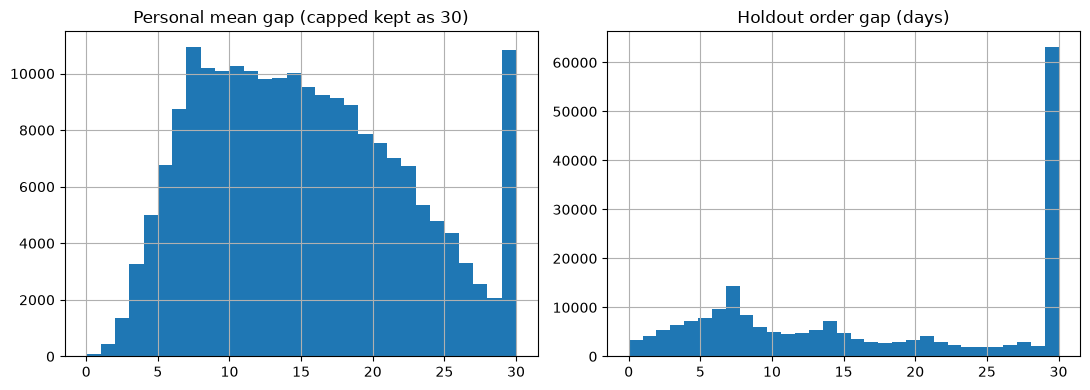

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["mean_gap"].hist(bins=30, ax=ax[0]); ax[0].set_title("Personal mean gap (capped kept as 30)")
df["holdout_gap_days"].hist(bins=31, ax=ax[1]); ax[1].set_title("Holdout order gap (days)")
plt.tight_layout()
plt.savefig("../docs/gap_distributions.png", dpi=120)

Cell 7: eligibility and z-score

In [7]:
MIN_GAPS = 5
SD_FLOOR = 1.0   # gaps are whole days, so an SD below 1 day is below the data's resolution

df["eligible"] = (df["rhythm_class"] != "all_capped") & (df["n_gaps"] >= MIN_GAPS)
df["sd_used"] = df["sd_gap"].clip(lower=SD_FLOOR)
df["z_holdout"] = (df["holdout_gap_days"] - df["mean_gap"]) / df["sd_used"]
df.loc[~df["eligible"], "z_holdout"] = np.nan

print(df.groupby("rhythm_class")["eligible"].agg(["sum", "mean"]).round(3))
print("eligible total:", df["eligible"].sum(), f"({df['eligible'].mean():.1%})")
print(df["z_holdout"].describe().round(2))

# check the finding above
print("holdout capped:", round(df["holdout_is_capped"].mean(), 3))
print("prior gaps capped (pooled):", round(df["n_capped_gaps"].sum() / df["n_gaps"].sum(), 3))

                  sum   mean
rhythm_class                
all_capped          0  0.000
constant_gap       40  0.052
mostly_capped   12416  0.382
regular        133653  0.814
eligible total: 146109 (70.9%)
count    146109.00
mean          0.32
std           1.63
min         -28.80
25%          -0.64
50%           0.09
75%           1.06
max          29.60
Name: z_holdout, dtype: float64
holdout capped: 0.306
prior gaps capped (pooled): 0.102


Cell 8: how many users each z cut-off labels

In [8]:
elig = df[df["eligible"]]
for z in [1, 1.5, 2, 3]:
    late = elig["z_holdout"] >= z
    unknown = (~late) & elig["holdout_is_capped"]
    on_time = (~late) & (~elig["holdout_is_capped"])
    print(f"z >= {z:<3}: late {late.mean():5.1%} | unknown {unknown.mean():5.1%} | on time {on_time.mean():5.1%}")

z >= 1  : late 26.6% | unknown  7.1% | on time 66.3%
z >= 1.5: late 15.4% | unknown 14.1% | on time 70.5%
z >= 2  : late  9.0% | unknown 18.4% | on time 72.6%
z >= 3  : late  3.8% | unknown 21.7% | on time 74.5%


Cell 9: H1. Is the final gap more often capped than a user’s own earlier gaps?

In [11]:
from scipy import stats

print("holdout capped (per user):    ", round(df["holdout_is_capped"].mean(), 3))
print("prior capped share (per user):", round(df["pct_capped_gaps"].mean(), 3))

# Paired test: each user against their own history
d = df["holdout_is_capped"].astype(float) - df["pct_capped_gaps"]
print("mean paired difference:", round(d.mean(), 3))
print(stats.ttest_1samp(d, 0))
print(stats.wilcoxon(d))   # nonparametric check

# Does it hold at every tenure level?
df["tenure_bin"] = pd.cut(df["n_prior_orders"], [0, 4, 9, 19, 99], labels=["3-4", "5-9", "10-19", "20+"])
df.groupby("tenure_bin", observed=True).agg(
    users=("user_id", "size"),
    holdout=("holdout_is_capped", "mean"),
    prior=("pct_capped_gaps", "mean"),
).round(3)

holdout capped (per user):     0.306
prior capped share (per user): 0.229
mean paired difference: 0.078
TtestResult(statistic=np.float64(78.21532420970657), pvalue=np.float64(0.0), df=np.int64(206208))
WilcoxonResult(statistic=np.float64(4510967895.0), pvalue=np.float64(0.0))


,users,holdout,prior
tenure_bin,,,
3-4,43576,0.471,0.396
5-9,60937,0.401,0.310
10-19,50965,0.271,0.176
20+,50731,0.087,0.039


Cell 10: H2. Does “z ≥ 2” really mean a 2.3% tail?

In [10]:
elig = df[df["eligible"]]
z = elig["z_holdout"]

print("skewness:", round(stats.skew(z), 2), "| excess kurtosis:", round(stats.kurtosis(z), 2))
print("share with |z| > 10:", round((z.abs() > 10).mean(), 4))

late, n = int((z >= 2).sum()), len(z)
expected = 1 - stats.norm.cdf(2)
print(f"empirical z>=2: {late/n:.2%} vs normal expectation {expected:.2%}")
print(stats.binomtest(late, n, expected, alternative="greater"))

skewness: 1.95 | excess kurtosis: 36.13
share with |z| > 10: 0.0026
empirical z>=2: 9.00% vs normal expectation 2.28%
BinomTestResult(k=13147, n=146109, alternative='greater', statistic=0.08998076778295656, pvalue=0.0)


Cell 11: does the tail shrink with more history?

In [12]:
elig = df[df["eligible"]].copy()
elig["gaps_bin"] = pd.cut(elig["n_gaps"], [4, 7, 12, 20, 98], labels=["5-7", "8-12", "13-20", "21+"])

elig.groupby("gaps_bin", observed=True).agg(
    users=("user_id", "size"),
    tail_z2=("z_holdout", lambda s: (s >= 2).mean()),
    holdout_capped=("holdout_is_capped", "mean"),
).round(3)

,users,tail_z2,holdout_capped
gaps_bin,,,
5-7,35385,0.068,0.394
8-12,35644,0.071,0.318
13-20,29976,0.096,0.219
21+,45104,0.118,0.076


Cell 12: compare against a rule that doesn’t assume bell-shaped gaps

In [13]:
# Ratio rule: final gap at least twice the user's own typical (median) gap
elig["ratio"] = elig["holdout_gap_days"] / elig["median_gap"].clip(lower=1)
elig["late_z"]     = elig["z_holdout"] >= 2
elig["late_ratio"] = elig["ratio"] >= 2

print(pd.crosstab(elig["late_z"], elig["late_ratio"], normalize=True).round(3))
print("late by z-rule:    ", round(elig["late_z"].mean(), 3))
print("late by ratio rule:", round(elig["late_ratio"].mean(), 3))

late_ratio  False  True 
late_z                  
False       0.766  0.144
True        0.004  0.086
late by z-rule:     0.09
late by ratio rule: 0.23


Cell 13: placebo test (separates explanation 1 from 2)

In [14]:
placebo = pd.read_sql("""
WITH hist AS (
    SELECT user_id, COUNT(*) AS n_h, AVG(gap_days) AS mean_h, STDDEV_SAMP(gap_days) AS sd_h
    FROM analytics.user_order_timeline
    WHERE eval_set = 'prior' AND gap_days IS NOT NULL AND orders_from_end >= 3
    GROUP BY user_id
)
SELECT t.user_id, t.gap_days AS placebo_gap, t.is_capped_gap AS placebo_capped,
       h.mean_h, h.sd_h
FROM analytics.user_order_timeline t
JOIN hist h USING (user_id)
WHERE t.orders_from_end = 2 AND h.n_h >= 5
""", engine)

placebo["z_placebo"] = (placebo["placebo_gap"] - placebo["mean_h"]) / placebo["sd_h"].clip(lower=SD_FLOOR)

cmp = (elig[["user_id", "z_holdout", "holdout_is_capped"]]
       .merge(placebo[["user_id", "z_placebo", "placebo_capped"]], on="user_id"))

print("users compared:", len(cmp))
print("tail z>=2   holdout:", round((cmp["z_holdout"] >= 2).mean(), 3),
      "| placebo:", round((cmp["z_placebo"] >= 2).mean(), 3))
print("capped      holdout:", round(cmp["holdout_is_capped"].mean(), 3),
      "| placebo:", round(cmp["placebo_capped"].mean(), 3))

users compared: 132512
tail z>=2   holdout: 0.092 | placebo: 0.081
capped      holdout: 0.224 | placebo: 0.184


Cell 14: a proper paired test for the placebo comparison

In [15]:
from statsmodels.stats.contingency_tables import mcnemar

for label, a, b in [
    ("z >= 2", cmp["z_holdout"] >= 2, cmp["z_placebo"] >= 2),
    ("capped", cmp["holdout_is_capped"], cmp["placebo_capped"]),
]:
    tbl = pd.crosstab(a, b)
    print(label)
    print(tbl)
    print(mcnemar(tbl.values, exact=False, correction=True))
    print()

z >= 2
z_placebo   False  True 
z_holdout               
False      112177   8155
True         9565   2615
pvalue      3.5084996187506685e-26
statistic   112.03617381489842

capped
placebo_capped     False  True 
holdout_is_capped              
False              88661  14148
True               19460  10243
pvalue      1.5518457820283908e-184
statistic   839.285914068079

